# PURF — MNIST exploration notebook
A companion to the Streamlit app. It reuses the project's `src` modules, so every number here matches the app.

Dataset: Kaggle **hojjatk/mnist-dataset** (original MNIST IDX files).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, matplotlib.pyplot as plt
from src.data_loader import load_mnist, get_splits
from src.data_validation import validate_dataset
from src.eda import compute_stats

data = load_mnist()
splits = get_splits(data=data)
print('source:', data.source)
print('train', splits.x_train.shape, 'val', splits.x_val.shape, 'test', splits.x_test.shape)

source: kaggle:hojjatk/mnist-dataset
train (54000, 28, 28) val (6000, 28, 28) test (10000, 28, 28)


## 1. Validation checks

In [2]:
rep = validate_dataset(data)
for c in rep['checks']:
    print('PASS' if c['passed'] else 'FAIL', '-', c['check'], '-', c['detail'])

PASS - train: image shape - (60000, 28, 28) (expected (60000, 28, 28))
PASS - train: image dtype uint8 - uint8
PASS - train: label count matches images - 60000 labels / 60000 images
PASS - train: pixel range 0-255 - min=0, max=255
PASS - train: labels are digits 0-9 - unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
PASS - train: no severe class imbalance (max/min < 1.5) - max/min ratio = 1.244
PASS - train: no blank images - 0 blank images
PASS - test: image shape - (10000, 28, 28) (expected (10000, 28, 28))
PASS - test: image dtype uint8 - uint8
PASS - test: label count matches images - 10000 labels / 10000 images
PASS - test: pixel range 0-255 - min=0, max=255
PASS - test: labels are digits 0-9 - unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
PASS - test: no severe class imbalance (max/min < 1.5) - max/min ratio = 1.272
PASS - test: no blank images - 0 blank images


## 2. Samples

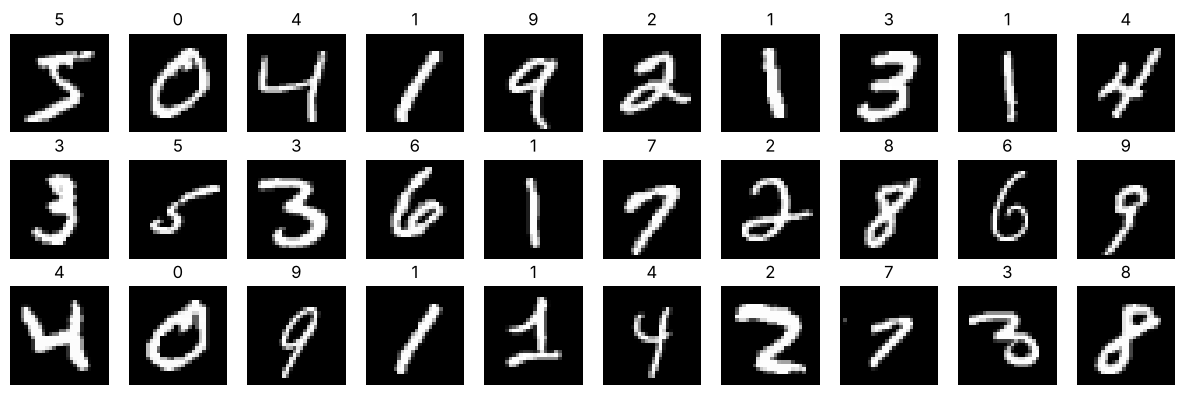

In [3]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for ax, i in zip(axes.ravel(), range(30)):
    ax.imshow(splits.x_train[i], cmap='gray'); ax.set_title(int(splits.y_train[i])); ax.axis('off')
plt.tight_layout()

## 3. Class distribution and statistics

class counts (train): [5331, 6068, 5362, 5518, 5258, 4879, 5326, 5638, 5266, 5354]
zero pixels: 80.9%  mean pixel: 33.32


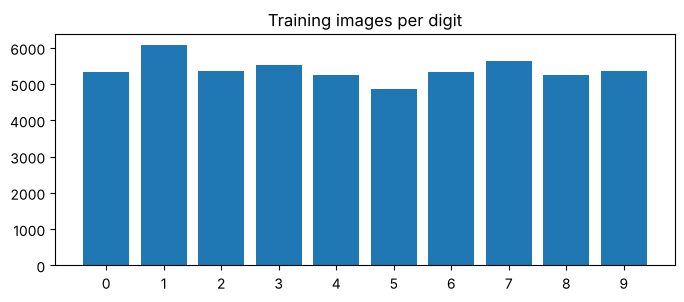

In [4]:
stats = compute_stats(splits)
print('class counts (train):', stats['class_counts']['train'])
print(f"zero pixels: {stats['fraction_zero_pixels']*100:.1f}%  mean pixel: {stats['pixel_mean']:.2f}")
plt.figure(figsize=(8,3)); plt.bar(range(10), stats['class_counts']['train']); plt.xticks(range(10)); plt.title('Training images per digit');

## 4. Average digit per class

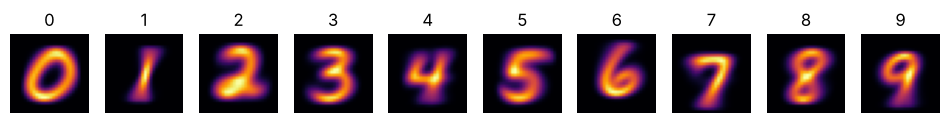

In [5]:
from src.eda import class_mean_images
means = class_mean_images(splits.x_train, splits.y_train)
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for d in range(10):
    axes[d].imshow(means[d], cmap='inferno'); axes[d].set_title(d); axes[d].axis('off')

## 5. Automatic insights

In [6]:
for line in stats['insights']:
    print('-', line, '\n')

- The 60,000-image training set is close to balanced: digit 1 is the most frequent (6,742 images) and digit 5 the least (5,421), a ratio of 1.24. Accuracy is therefore a fair headline metric, but per-class recall is still reported. 

- 80.9% of all pixels are exactly 0 (background) and only 0.7% are fully saturated (255) — images are sparse, with anti-aliased stroke edges producing the intermediate grey values. 

- Digit 1 uses the least ink (≈60 bright pixels on average) and is the narrowest (mean width 8.2px), while digit 0 uses the most (≈138 px). Ink amount alone carries some class information. 

- Digit 2 shows the highest pixel-level variability across writers and digit 1 the lowest, i.e. some digits are written in many more styles than others (slant, loops, open/closed tops). 

- The most similar class-average images (cosine similarity) are 4↔9 (0.926), 5↔8 (0.912), 3↔5 (0.898). Pairs that overlap heavily in pixel space are the ones a pixel-based model is most likely to confuse.

## 6. Trained model results (if the pipeline has been run)

In [7]:
import json
from src.config import SUMMARY_PATH
if SUMMARY_PATH.exists():
    s = json.loads(SUMMARY_PATH.read_text())
    print('TRAX =', s['production_model'])
    for k, v in s['results'].items():
        print(f"{k:<22} val {v['val']['accuracy']*100:6.2f}%   test {v['test']['accuracy']*100:6.2f}%")
else:
    print('Run: python -m src.train --all')

TRAX = cnn_tuned
logistic_regression    val  91.88%   test  92.18%
knn                    val  97.72%   test  97.64%
svm                    val  98.00%   test  97.82%
ann                    val  98.20%   test  98.13%
cnn_baseline           val  98.92%   test  99.15%
cnn_tuned              val  99.17%   test  99.51%
cnn_tuned_aug          val  99.03%   test  99.39%
